In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## data-mixture

**Figure 1: Pretraining data mixture over training under the three-stage curriculum.** Each area is a domain's share of training tokens; the stages switch at 30k and 70k steps. Web text falls from 62% to 40% of tokens, while code grows from 12% to 24% and math from 6% to 18%.

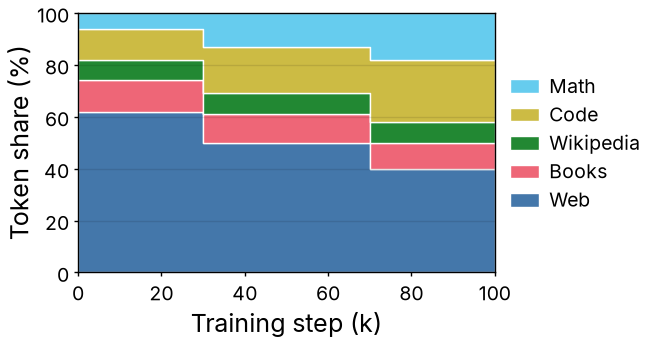

In [2]:
with open("../data-mixture.json") as f:
    data = json.load(f)

steps = np.array(data["steps"]) / 1000
domains = ["Web", "Books", "Wikipedia", "Code", "Math"]
shares = [np.array(data["shares"][d]) * 100 for d in domains]
series_colors = [colors["series-1"], colors["series-2"], colors["series-3"], colors["series-4"], colors["series-5"]]

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.stackplot(steps, shares, colors=series_colors, labels=domains, edgecolor="white", linewidth=0.5, step="post")
ax.set_ylim(0, 100)
ax.margins(x=0)
ax.set_axisbelow(False)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Training step (k)")
ax.set_ylabel("Token share (%)")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("data-mixture.pdf")
fig.savefig("data-mixture.png")
plt.show()